In [1]:
import itertools
from ast import literal_eval
import os

import numpy as np
import pandas as pd
from scipy.integrate import trapezoid

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MaxNLocator
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns

from mg_sampling import PROJECT_DIR
from mg_sampling.constants import RT
from mg_sampling.tools import read_plumed, read_plumed_fes, range_to_edges, edges_to_range, finitemin, finitemax, block_analysis, read_wsv, demux
from mg_sampling.bias import bias_fn

LABELS = {
    'amber_tip3p': "Amber/TIP3P",
    'mMg_tip3p': "microMg/TIP3P",
    'nMg_tip3p': "nanoMg/TIP3P", 
    'mMg_opc': "microMg/OPC",
    'ecc_spce': "AmberECC/SPCE",
}

FORCEFIELDS_ARCHIVE = ['amber_tip3p', 'mMg_tip3p', 'nMg_tip3p', 'mMg_opc', 'ecc_spce']
FORCEFIELDS = ['mMg_tip3p']

os.makedirs('figures/replex', exist_ok=True)
os.makedirs('figures/replex/archive', exist_ok=True)

## Figure 1

Metadynamics.

In [14]:
def plot_metad_fes(path, ax):
    colvar = read_plumed(f'{path}/COLVAR')
    bins = np.linspace(0, 2, 41), np.linspace(4, 7, 61)

    bias = colvar['metad.bias']  # kJ/mol
    weights = np.exp(bias/RT)

    # Remove nop == 0
    x, y = colvar['nop'], colvar['now']
    weights[x <= 0] = 0

    ρ_avg, x_edges, y_edges = np.histogram2d(x, y, bins=bins, density=True, weights=weights)
    fes = -np.log(ρ_avg)
    fes -= finitemin(fes)

    extent = [*x_edges[[0, -1]], *y_edges[[0, -1]]]
    levels = np.arange(0, finitemax(fes), 2)

    im = ax.imshow(fes.T, extent=extent, origin='lower', aspect=1, cmap='RdPu_r')
    cf = ax.contour(fes.T, colors=['black'], linewidths=[1, 0.2], extent=extent, levels=levels)
    cbar = plt.colorbar(im)
    cbar.add_lines(cf)
    cbar.set_label("FES [$k_\mathrm{B}T$]")

    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(False)
    ax.plot([0, 1, 2, 1, 0], [6, 7, 6, 5, 6], color='white', linestyle='dashed', linewidth=1)

    ax.set_xlabel("$n_\mathrm{O_P}$")
    ax.set_ylabel("$n_\mathrm{O_W}$")

/scratch_local/ipykernel_3228491/167495812.py:28: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)


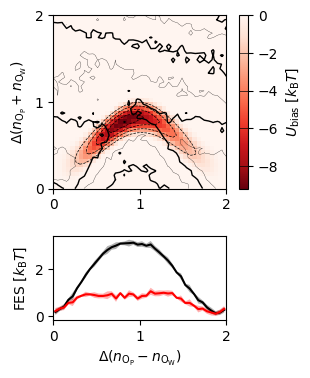

In [ ]:
def plot_barrier(path, ax1, ax2):

    colvar = read_plumed(f'{path}/COLVAR')
    params = read_wsv(f'{path}/bias_params.wsv').iloc[0]

    X_edges = np.linspace(0, 2, 41)
    Y_edges = np.linspace(0, 2, 41)
    bins = (X_edges, Y_edges)
    X_range = edges_to_range(X_edges)
    Y_range = edges_to_range(Y_edges)

    bias = colvar['metad.bias']  # kJ/mol
    weights = np.exp(bias/RT)

    # Remove nop == 0
    x = colvar['nop']
    y = colvar['now']
    X = colvar['nop'] - colvar['now'] + 6
    Y = colvar['nop'] + colvar['now'] - 6
    weights[X <= 0] = 0
    weights[X > 2] = 0
    weights[Y <= 0] = 0
    weights[Y > 2] = 0

    ρ_avg, _, _ = np.histogram2d(X, Y, bins=bins, density=True, weights=weights)
    fes = -np.log(ρ_avg)
    fes -= finitemin(fes)

    extent = [*X_edges[[0, -1]], *Y_edges[[0, -1]]]
    levels = np.arange(0, finitemax(fes), 2)

    #im = ax1.imshow(fes.T, extent=extent, origin='lower', aspect=1, cmap='RdPu_r')
    cf = ax1.contour(fes.T, colors=['black'], linewidths=[1, 0.2], extent=extent, levels=levels)

    # Show bias
    XX, YY = np.meshgrid(X_range, Y_range, indexing='ij')
    u = bias_fn((XX + YY)/2, YY - (XX+YY)/2 + 6, *params)
    im = ax1.imshow(u.T, extent=extent, origin='lower', aspect=1, cmap='Reds_r')
    cbar = plt.colorbar(im, ax=ax1, fraction=0.05)
    cf = ax1.contour(u.T, colors=['black'], linewidths=0.5, extent=extent, levels=-levels[::-1])
    cbar.add_lines(cf)
    cbar.set_label("$U_\mathrm{bias}$ [$k_\mathrm{B}T$]")

    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax1.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax1.tick_params(labelbottom=True)

    #ax.set_xlabel("$\Delta (n_\mathrm{O_P} - n_\mathrm{O_W})$")
    ax1.set_ylabel("$\Delta (n_\mathrm{O_P} + n_\mathrm{O_W})$")
    ax1.grid(False)

    # Block analysis for error on FES projection
    def get_F_X(X, Y, weights):
        ρ_avg, _, _ = np.histogram2d(X, Y, bins=bins, density=True, weights=weights)
        ρ_X = trapezoid(ρ_avg, X_range, axis=1)
        F_X = -np.log(ρ_X)
        F_X -= finitemin(F_X)
        return F_X

    F_X_mean, F_X_stderr = block_analysis(X, Y, weights, func=get_F_X)
    ax2.plot(X_range, F_X_mean, color='black')
    ax2.fill_between(X_range, F_X_mean - 1.96*F_X_stderr, F_X_mean + 1.96*F_X_stderr, alpha=0.3, facecolor='black')

    # Bias weighted
    weights = weights * np.exp(-bias_fn(x, y, *params)/RT)
    F_X_mean, F_Y_stderr = block_analysis(X, Y, weights, func=get_F_X)
    ax2.plot(X_range, F_X_mean, color='red')
    ax2.fill_between(X_range, F_X_mean - 1.96*F_X_stderr, F_X_mean + 1.96*F_X_stderr, alpha=0.3, facecolor='red')

    ax2.set_xlabel("$\Delta (n_\mathrm{O_P} - n_\mathrm{O_W})$")
    ax2.set_ylabel("FES [$k_\mathrm{B}T$]")

ff = 'mMg_tip3p'
fig, axarr = plt.subplots(nrows=2, height_ratios=(3, 1), sharex=True, figsize=(3, 4), constrained_layout=True)
plot_barrier(PROJECT_DIR / f'metad/op_{ff}', *axarr)

/scratch_local/ipykernel_3228491/2472695877.py:30: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)


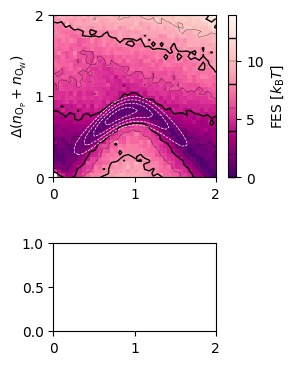

In [ ]:
def plot_predicted(path, ax1):

    colvar = read_plumed(f'{path}/COLVAR')
    params = read_wsv(f'{path}/bias_params.wsv').iloc[0]

    X_edges = np.linspace(0, 2, 41)
    Y_edges = np.linspace(0, 2, 41)
    bins = (X_edges, Y_edges)
    X_range = edges_to_range(X_edges)
    Y_range = edges_to_range(Y_edges)

    bias = colvar['metad.bias']  # kJ/mol
    weights = np.exp(bias/RT)

    # Remove nop == 0
    x = colvar['nop']
    y = colvar['now']
    X = colvar['nop'] - colvar['now'] + 6
    Y = colvar['nop'] + colvar['now'] - 6
    weights[X <= 0] = 0
    weights[X > 2] = 0
    weights[Y <= 0] = 0
    weights[Y > 2] = 0

    weights = weights * np.exp(-bias_fn(x, y, *params)/RT)

    ρ_avg, _, _ = np.histogram2d(X, Y, bins=bins, density=True, weights=weights)
    fes = -np.log(ρ_avg)
    fes -= finitemin(fes)

    extent = [*X_edges[[0, -1]], *Y_edges[[0, -1]]]
    levels = np.arange(0, finitemax(fes), 2)

    im = ax1.imshow(fes.T, extent=extent, origin='lower', aspect=1, cmap='RdPu_r')
    cf = ax1.contour(fes.T, colors=['black'], linewidths=[1, 0.2], extent=extent, levels=levels)

    # Show bias
    XX, YY = np.meshgrid(X_range, Y_range, indexing='ij')
    u = bias_fn((XX + YY)/2, YY - (XX+YY)/2 + 6, *params)
    #im = ax1.imshow(u.T, extent=extent, origin='lower', aspect=1, cmap='Reds_r')
    cbar = plt.colorbar(im, ax=ax1, fraction=0.05)
    cbar.add_lines(cf)
    cf = ax1.contour(u.T, colors=['white'], linewidths=0.5, extent=extent, levels=-levels[::-1])
    cbar.set_label("FES [$k_\mathrm{B}T$]")

    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax1.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax1.tick_params(labelbottom=True)

    #ax.set_xlabel("$\Delta (n_\mathrm{O_P} - n_\mathrm{O_W})$")
    ax1.set_ylabel("$\Delta (n_\mathrm{O_P} + n_\mathrm{O_W})$")
    ax1.grid(False)



ff = 'mMg_tip3p'
fig, axarr = plt.subplots(nrows=2, height_ratios=(3, 1), sharex=True, figsize=(3, 4), constrained_layout=True)
plot_predicted(PROJECT_DIR / f'metad/op_{ff}', axarr[0])

/scratch_local/ipykernel_3228491/3979435711.py:13: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_3228491/167495812.py:28: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_3228491/2472695877.py:30: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_3228491/3979435711.py:13: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_3228491/167495812.py:28: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_3228491/2472695877.py:30: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_3228491/3979435711.py:13: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_3228491/167495812.py:28: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_lo

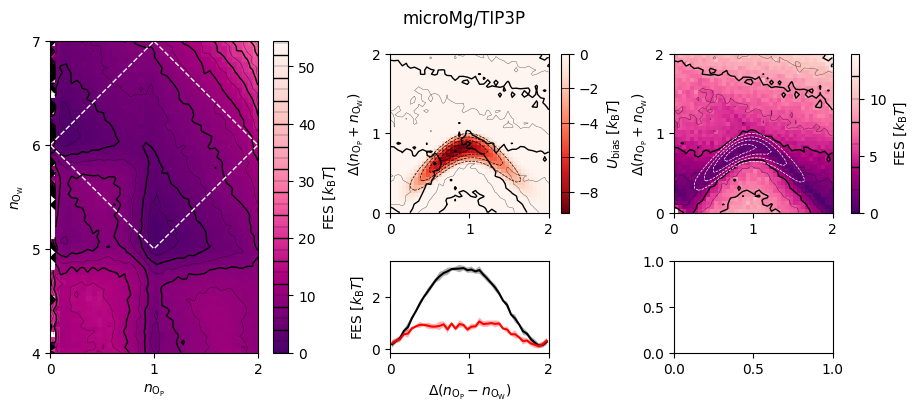

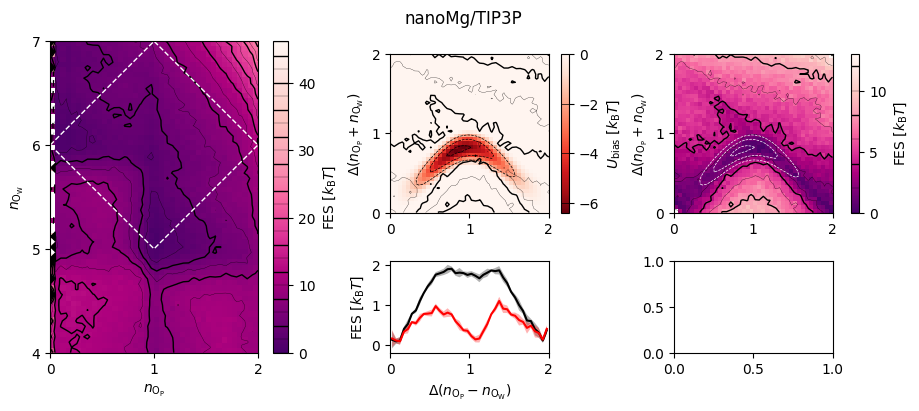

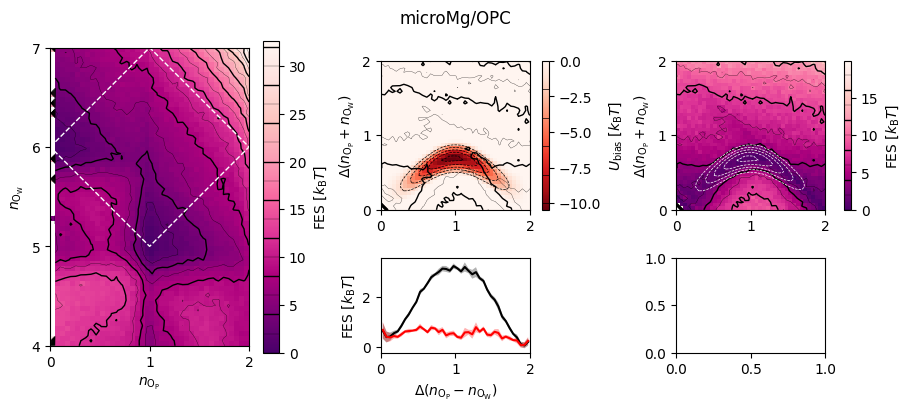

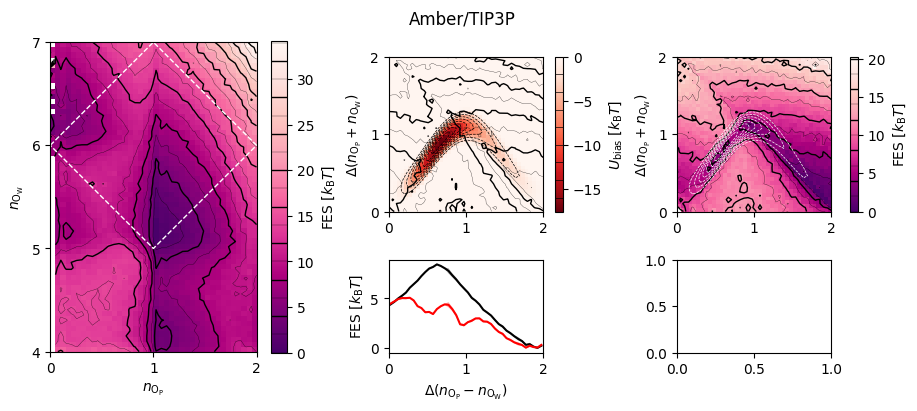

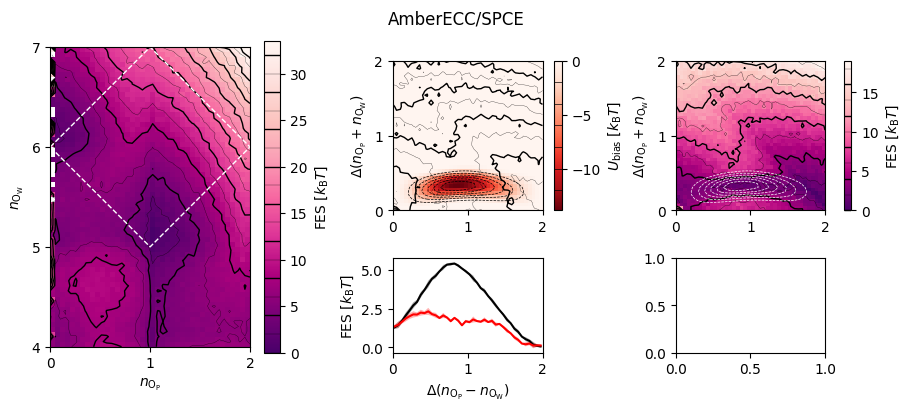

In [29]:
for ff in ['mMg_tip3p', 'nMg_tip3p', 'mMg_opc', 'amber_tip3p', 'ecc_spce']:

    fig = plt.figure(constrained_layout=True, figsize=(9, 4))
    gs = fig.add_gridspec(ncols=3, nrows=2, height_ratios=(2, 1), width_ratios=(4, 3, 3))

    ax = fig.add_subplot(gs[:, 0])

    plot_metad_fes(PROJECT_DIR / f'metad/op_{ff}', ax)

    ax1 = fig.add_subplot(gs[0, 1])
    ax2 = fig.add_subplot(gs[1, 1], sharex=ax1)
    plot_barrier(PROJECT_DIR / f'metad/op_{ff}', ax1, ax2)

    ax3 = fig.add_subplot(gs[0, 2])
    ax4 = fig.add_subplot(gs[1, 2])
    fig.suptitle(LABELS[ff])
    plot_predicted(PROJECT_DIR / f'metad/op_{ff}', ax3)
    plt.savefig(f'paper_figures/bias_design_{ff}.pdf')

/scratch_local/ipykernel_258782/3198843088.py:3: RuntimeWarning: divide by zero encountered in log
  plt.plot(edges_to_range(d_edges), -RT*np.log(ρ_d))
/scratch_local/ipykernel_258782/3198843088.py:8: RuntimeWarning: divide by zero encountered in log
  plt.plot(edges_to_range(d_edges), -RT*np.log(ρ_d))


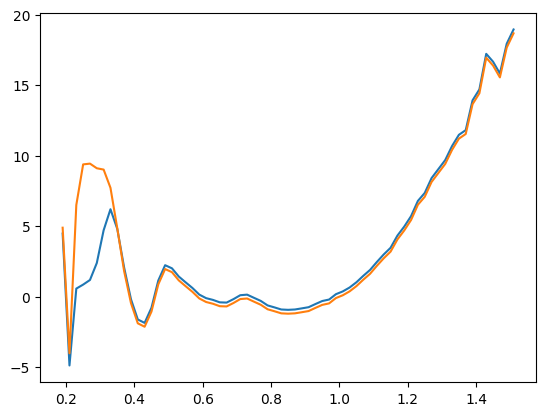

In [4]:
colvar = read_plumed(PROJECT_DIR / 'kinetics/op_mMg_tip3p/1.0/COLVAR')
ρ_d, d_edges = np.histogram(colvar['dop1'], bins=np.linspace(0, 2, 101), density=True)
plt.plot(edges_to_range(d_edges), -RT*np.log(ρ_d))

weights = np.exp(colvar['bias.bias'] / RT)
weights /= weights.sum()
ρ_d, d_edges = np.histogram(colvar['dop1'], bins=np.linspace(0, 2, 101), density=True, weights=weights)
plt.plot(edges_to_range(d_edges), -RT*np.log(ρ_d))



/scratch_local/ipykernel_2626460/3434901206.py:1: RuntimeWarning: divide by zero encountered in log
  plt.plot(edges_to_range(d_edges), -RT*np.log(ρ_d))


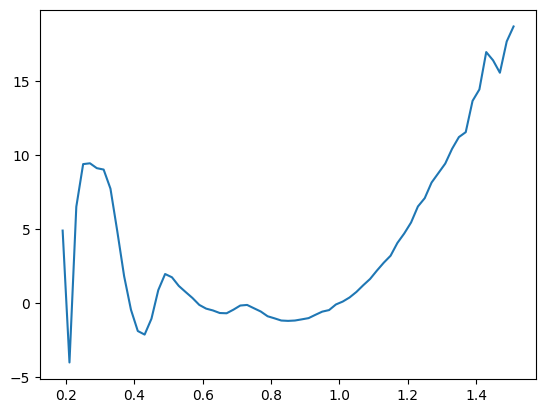

In [88]:
plt.plot(edges_to_range(d_edges), -RT*np.log(ρ_d))

In [92]:
colvar

,time,nop,now,lwall.bias,uwall.bias,metad.bias
0,0.0,0.000000,6.000065,0.0,0.0,155.584121
1,1.0,0.000000,6.144692,0.0,0.0,157.246189
2,2.0,0.000000,6.172999,0.0,0.0,157.112615
3,3.0,0.000000,6.308400,0.0,0.0,156.299424
4,4.0,0.000000,6.266627,0.0,0.0,156.577665
...,...,...,...,...,...,...
399996,399996.0,0.615347,5.534115,0.0,0.0,109.665516
399997,399997.0,0.667728,5.266949,0.0,0.0,111.106298
399998,399998.0,0.920989,5.006728,0.0,0.0,121.550582
399999,399999.0,0.724731,5.012459,0.0,0.0,111.529071


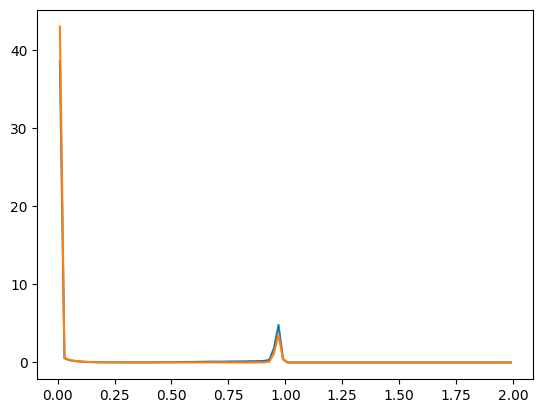

In [97]:
colvar = read_plumed(PROJECT_DIR / 'kinetics/op_mMg_tip3p/1.0/COLVAR')

ρ_d, d_edges = np.histogram(colvar['cv.nb-0'], bins=np.linspace(0, 2, 101), density=True)
plt.plot(edges_to_range(d_edges), ρ_d)

weights = np.exp(colvar['bias.bias'] / RT)
weights /= weights.sum()
ρ_d, d_edges = np.histogram(colvar['cv.nb-0'], bins=np.linspace(0, 2, 101), density=True, weights=weights)
plt.plot(edges_to_range(d_edges), ρ_d)

/scratch_local/ipykernel_2626460/3434901206.py:1: RuntimeWarning: divide by zero encountered in log
  plt.plot(edges_to_range(d_edges), -RT*np.log(ρ_d))


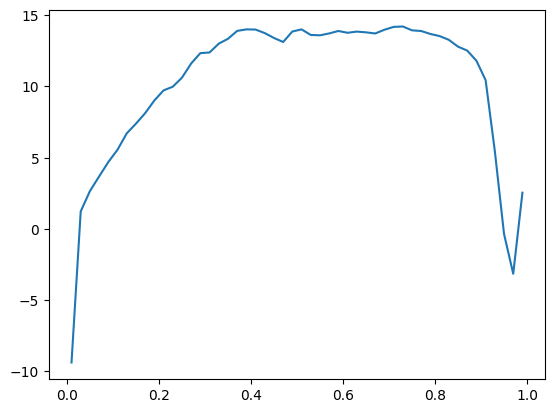

In [98]:
plt.plot(edges_to_range(d_edges), -RT*np.log(ρ_d))

In [ ]:
if ax is None:
    _, ax = plt.subplots()

if method == 'hills':
    fes = sim.fes - sim.fes.min()
    x_edges, y_edges = range_to_edges(sim.x_range), range_to_edges(sim.y_range)
elif method == 'reweight':
    x, y = sim.colvar[sim.x_name], sim.colvar[sim.y_name]
    bias = sim.colvar['metad.bias']
    weights = np.exp(bias/RT)
    weights /= weights.mean()
    ρ_avg, x_edges, y_edges = np.histogram2d(x, y, bins=bins, density=True, weights=weights)
    fes = -RT * np.log(ρ_avg)
    fes -= finitemin(fes)

extent = [*x_edges[[0, -1]], *y_edges[[0, -1]]]

im = ax.imshow(fes.T, extent=extent, origin='lower', aspect=1, cmap='RdPu_r')
levels = RT * np.arange(np.floor(finitemin(fes)/RT), np.ceil(finitemax(fes)/RT))
cf = ax.contour(fes.T, colors='black', linewidths=[1, 0.5], extent=extent, levels=levels)
cbar = plt.colorbar(im)
cbar.add_lines(cf)
cbar.ax.set_ylabel(r'FES [kJ/mol]')
ax.set_title(sim.name)
ax.set_xlabel(LABELS[sim.x_name])
ax.set_ylabel(LABELS[sim.y_name])
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(color='black', linestyle='solid', linewidth=0.5)
ax.xaxis.set_zorder(10)
ax.yaxis.set_zorder(10)

return ax

## Figure 2

Time evolution of the number of inner-bound ions

In [99]:
systems = ['7ez0', '7ez0_noion', '7ez0_2', '7ez0_noion_2']
forcefields = ['mMg_opc', 'mMg_tip3p', 'nMg_tip3p']
repids = [0]
ions = ['MG', 'NA']
df = []

for system, forcefield, repid in itertools.product(systems, forcefields, repids):
    path = PROJECT_DIR / 'replex' / system / forcefield / f'rep{repid:02d}'
    _df = pd.read_csv(path / f'ion_analysis.csv', na_filter=False, converters={'inner_names': literal_eval, 'inner_resids': literal_eval, 'inner_resnames': literal_eval, 'inner_indices': literal_eval, 'outer_names': literal_eval, 'outer_resnames': literal_eval})
    _df = _df.loc[_df['time'] % 1000.0 == 0]
    _df['system'] = system.removesuffix('_2')
    _df['forcefield'] = forcefield
    _df['repid'] = repid
    _df['replicate'] = 1 if system.endswith('_2') else 0
    df.append(_df)
df = pd.concat(df)
for col in ['name', 'mgrna', 'forcefield', 'system']:
    df[col] = df[col].astype('category')

ref = pd.read_csv(PROJECT_DIR / 'structures' / '7ez0' / 'ion_analysis.csv', na_filter=False, converters={'inner_names': literal_eval, 'inner_resids': literal_eval, 'inner_resnames': literal_eval, 'inner_indices': literal_eval, 'outer_names': literal_eval, 'outer_resnames': literal_eval})
ref['system'] = '7ez0'
ref['forcefield'] = 'PDB'
ref['repid'] = 0
ref['replicate'] = 0

df = pd.concat([df, ref])

In [100]:
hue_order = forcefields
palette = sns.color_palette().as_hex()[:3]

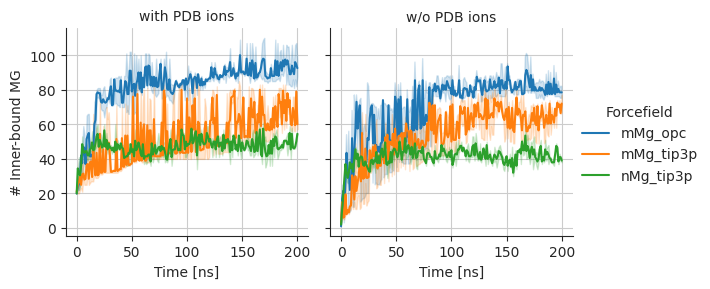

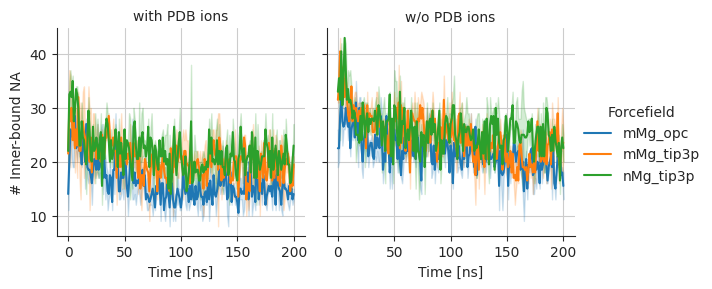

In [ ]:
sns.set_style("ticks", {'axes.grid': True})

for ion in ions:
    grouped = df.query(f"name == '{ion}' and forcefield != 'PDB' and time % 1000 == 0 and n_inner > 0").groupby(['time', 
        'system', 'replicate', 'forcefield'], observed=False).size().reset_index(name='counts')
    grouped['time_ns'] = grouped['time'] / 1000
    grouped['system_label'] = grouped['system'].map(lambda s: 'with PDB ions' if s == '7ez0' else 'w/o PDB ions')
    grouped.set_index('time_ns')

    g = sns.FacetGrid(grouped, col='system_label')

    g.map_dataframe(
        sns.lineplot,
        x='time_ns',
        y='counts',
        hue='forcefield',
        hue_order=hue_order,
        palette=palette,
    )

    g.add_legend(g._legend_data, title='Forcefield')
    g.set_ylabels(f"# Inner-bound {ion}")
    g.set_xlabels("Time [ns]")
    g.set_titles(r"{col_name}")
    plt.savefig(f'paper_figures/inner_bound_timeseries_{ion}.pdf')

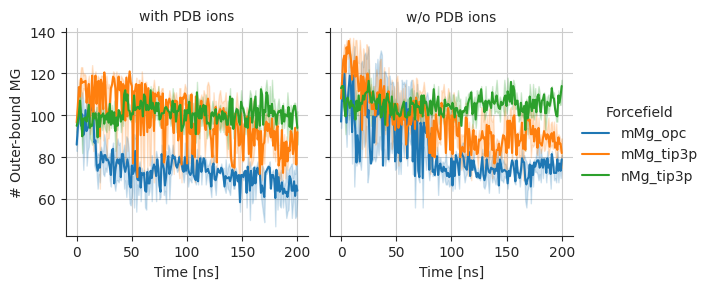

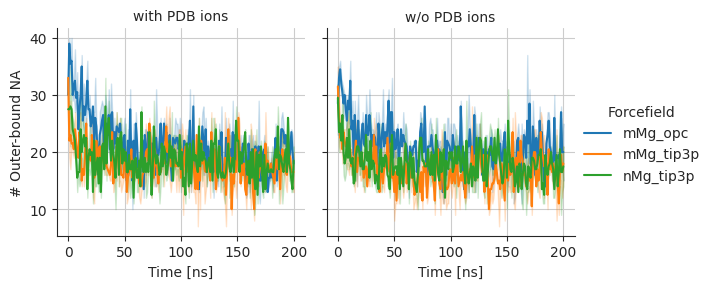

In [102]:
for ion in ions:
    grouped = df.query(f"name == '{ion}' and forcefield != 'PDB' and time % 1000 == 0 and n_inner == 0").groupby(['time', 
        'system', 'replicate', 'forcefield'], observed=False).size().reset_index(name='counts')
    grouped['time_ns'] = grouped['time'] / 1000
    grouped['system_label'] = grouped['system'].map(lambda s: 'with PDB ions' if s == '7ez0' else 'w/o PDB ions')
    grouped.set_index('time_ns')

    g = sns.FacetGrid(grouped, col='system_label')
    sns.set_style("ticks", {'axes.grid': True})

    g.map_dataframe(
        sns.lineplot,
        x='time_ns',
        y='counts',
        hue='forcefield',
        hue_order=hue_order,
        palette=palette,
    )

    g.add_legend(g._legend_data, title='Forcefield')
    g.set_ylabels(f"# Outer-bound {ion}")
    g.set_xlabels("Time [ns]")
    g.set_titles(r"{col_name}")
    plt.savefig(f'paper_figures/outer_bound_timeseries_{ion}.pdf')

In [78]:
df

,Unnamed: 0,frame,time,index,name,n_inner,inner_indices,inner_names,inner_resids,inner_resnames,...,forcefield,repid,replicate,n_outer,outer_indices,outer_names,outer_resids,outer_resnames,inner_dist,outer_dist
0,0,0,0.0,12443,MG,2,"[5966, 7723]","[O1P, O2P]","[207, 262]","[A, C]",...,mMg_opc,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,0,0.0,12444,MG,1,[2966],[O2P],[114],[A],...,mMg_opc,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,0,0.0,12445,MG,4,"[5226, 5289, 5323, 5356]","[O1P, O1P, O2P, O2P]","[184, 186, 187, 188]","[A, A, A, G]",...,mMg_opc,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,0,0.0,12446,MG,3,"[5193, 5227, 5290]","[O1P, O2P, O2P]","[183, 184, 186]","[A, A, A]",...,mMg_opc,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,0,0.0,12447,MG,2,"[4646, 4706]","[O2P, O1P]","[166, 168]","[C, U]",...,mMg_opc,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22,22,0,0.0,12464,MG,1,[4835],[O2P],[172],[A],...,PDB,0,0,11.0,"[4826, 4830, 4832, 4833, 4834, 4836, 4837, 486...","[C3', O2', O3', P, O1P, O5', C5', P, O2P, O5',...","[171, 171, 171, 172, 172, 172, 172, 173, 173, ...","[A, A, A, A, A, A, A, A, A, A, A]",[2.03066905744933],"[4.377157672220647, 4.133875987168322, 3.27183..."
23,23,0,0.0,12465,MG,0,[],[],[],[],...,PDB,0,0,6.0,"[683, 701, 703, 704, 4821, 4822]","[O2', C5, C4, O4, N1, C2]","[42, 43, 43, 43, 171, 171]","[A, U, U, U, A, A]",[],"[3.633002719210107, 4.163715510907822, 4.37701..."
24,24,0,0.0,12466,MG,0,[],[],[],[],...,PDB,0,0,1.0,[9340],[O6],[312],[G],[],[4.205565605189721]
25,25,0,0.0,12467,MG,1,[9132],[O1P],[306],[A],...,PDB,0,0,10.0,"[5998, 5999, 9067, 9068, 9069, 9130, 9131, 913...","[P, O1P, O3', P, O1P, O3', P, O2P, O5', O1P]","[208, 208, 303, 304, 304, 305, 306, 306, 306, ...","[C, C, G, A, A, U, A, A, A, U]",[2.2611957230826176],"[4.737698627515659, 3.3411686724130365, 4.0080..."


Gromacs restraint:

Positions $\mathbf{r}$ of the $N$ involved atoms. Reference positions $\mathbf{R}_i$. $k = k_x = k_y = k_z =$ 1000 kJ/mol/nm

$
V_{GMX}(\mathbf{r}) = \frac{k}{2}\sum_i^N | \mathbf{r}_i - \mathbf{R}_i | ^2
$

Plumed restraint:
$
\mathbf{δ}_{COM} = N^{-1}\sum_i^N (\mathbf{r}_i - \mathbf{R}_i)
$

$
V_{PMD}(\mathbf{r}) = \frac{κ}{2}N^{-1}\sum_i^N | \mathbf{r}_i - \mathbf{R}_i - \mathbf{δ}_{COM}| ^2
$

For $V_{GMX}$ we can assume on average $|\mathbf{δ}_{COM}| \ll | \mathbf{r}_i - \mathbf{R}_i |$ for a flexible molecule, with $|\mathbf{δ}_{COM}| = | \mathbf{r}_i - \mathbf{R}_i |$ for a totally rigid molecule. We can thus say

$
\langle V_{GMX} \rangle \approx \langle V_{PMD} \rangle
$

and identify $\frac{κ}{N} \approx k$. That is, GROMACS restraints on $N$ atoms with constant $k$ is similar to a PLUMED RMSD restraint with constant $Nk$.